# EUMETSearch quickstart

Minimal, self-contained example: search the EUMETSAT catalogue, download a single observation for a small area/time window, and plot it. Requires `EUMETSAT_CONSUMER_KEY` / `EUMETSAT_CONSUMER_SECRET` in a `.env` file (see the repo README).


In [1]:
from math import cos, radians
from datetime import datetime, timedelta

from eumetsearch import EUMDownloader, products_list
from eumetsearch.definitions import DATA_PATH

# Example: a single 10-minute SEVIRI observation over Porto, Portugal
center_lat_deg, center_lon_deg = 41.1103, -8.591
acquisition_date = "2024-07-23"
acquisition_hour = 12

start_time = datetime.strptime(acquisition_date, "%Y-%m-%d").replace(hour=acquisition_hour)
end_time = start_time + timedelta(minutes=10)

radius_km = 100
lat_delta = radius_km / 111.32
lon_delta = radius_km / (111.32 * cos(radians(center_lat_deg)))

# EUMDownloader expects bounding boxes as [N, S, W, E]
NSWE = [
    center_lat_deg + lat_delta,  # North
    center_lat_deg - lat_delta,  # South
    center_lon_deg - lon_delta,  # West
    center_lon_deg + lon_delta,  # East
]

product_id = products_list["MSG-SEVIRI-L1-HRY"]["product_id"]

downloader = EUMDownloader(
    product_id=product_id,
    output_dir=str(DATA_PATH / "datastore_data"),
)

file_list = downloader.download_single(
    start_time=start_time.strftime("%Y-%m-%dT%H:%M:%S"),
    end_time=end_time.strftime("%Y-%m-%dT%H:%M:%S"),
    bounding_box=NSWE,
    method="datatailor",
)
print(f"Found {len(file_list)} matching product(s); files written to {downloader.output_dir}")


Found 1 matching product(s); files written to ./data/datastore_data


## Plot the downloaded observation

The DataTailor output is a regular lat/lon-gridded netCDF — open it directly with `xarray`.


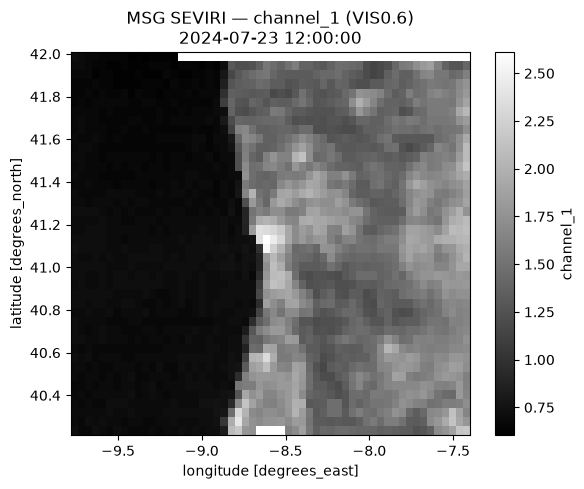

In [2]:
import xarray as xr
import matplotlib.pyplot as plt

# Pick the most recently downloaded file for this product
downloaded_files = sorted(
    (DATA_PATH / "datastore_data").glob(f"{downloader.product_name}_*.nc"),
    key=lambda p: p.stat().st_mtime,
)
ds = xr.open_dataset(downloaded_files[-1])

fig, ax = plt.subplots(figsize=(6, 5))
ds["channel_1"].plot(ax=ax, cmap="gray")  # channel_1 = VIS0.6
ax.set_title(f"MSG SEVIRI — channel_1 (VIS0.6)\n{start_time}")
plt.tight_layout()
plt.show()
